<table class="table table-bordered">
    <tr>
        <th style="text-align:center; width:25%"><img src='https://www.np.edu.sg/_next/image?url=https%3A%2F%2Fassets.app.optical.gov.sg%2Fnp%2Fproduction%2Fpublished%2Fcollections%2Fpages%2F17c64bb4-8632-49e9-af16-047f7cabe99a%2Fab16008f-a6a0-466e-9193-e16e947261b0.png&w=1080&q=75'"></th>
        <th style="text-align:center;"><h1>SCHOOL OF INFOCOMM TECHNOLOGY <br> Diploma in Data Science</h1><h2>Machine Learning 1: Assignment Coding</h2></th>
    </tr>
</table>


<div style="border:1px solid black; padding:10px; width:300px;"> <strong>
    Student Name:  Ethlind Leo Yee Qian
</div>



<span style="color:blue; font-size:1.2em;">
<strong>Note: This template provides suggested steps to guide your work. You may include additional steps where appropriate.</strong>
</span><br><br>


## Import the required packages

In [59]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [60]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, silhouette_score

In [61]:
import scipy.cluster.hierarchy as shc
from math import sqrt

## 1. Task 1: Supervised Learning Using Wine Quality Dataset

The aim of Task 1 is to predict the wine quality score. The target is `quality`. The other numeric columns are the input features. This is a regression task because the target is a number.

I used Linear Regression and Decision Tree Regression. Linear Regression is a simple model. Decision Tree can find different patterns in the data. I compare the models using MAE, RMSE and R².

### 1.1 Load and Explore the Data

First, I checked the dataset to understand it better. I looked at the number of rows and columns, data types, missing values, duplicate rows and summary statistics. I also used charts to understand the data before building the models.

In [62]:
# Load the wine data and show the first five rows
wine = pd.read_csv("Dataset/Data/winequality-white.csv")
wine.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


In [63]:
# Check the data size and data types
print("Number Of Rows And Columns:", wine.shape)

print()

wine.info()

Number Of Rows And Columns: (4898, 12)

<class 'pandas.DataFrame'>
RangeIndex: 4898 entries, 0 to 4897
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         4898 non-null   float64
 1   volatile acidity      4898 non-null   float64
 2   citric acid           4898 non-null   float64
 3   residual sugar        4898 non-null   float64
 4   chlorides             4898 non-null   float64
 5   free sulfur dioxide   4898 non-null   float64
 6   total sulfur dioxide  4898 non-null   float64
 7   density               4898 non-null   float64
 8   pH                    4898 non-null   float64
 9   sulphates             4898 non-null   float64
 10  alcohol               4898 non-null   float64
 11  quality               4898 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 459.3 KB


In [64]:
# Check missing values and duplicate rows
print(wine.isnull().sum())

print()

print("Duplicate Rows:", wine.duplicated().sum())

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Duplicate Rows: 937


In [65]:
# Show the data summary
wine.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000
mean,6.854788,0.278241,0.334192,6.391415,0.045772,35.308085,138.360657,0.994027,3.188267,0.489847,10.514267,5.877909
std,0.843868,0.100795,0.121020,5.072058,0.021848,17.007137,42.498065,0.002991,0.151001,0.114126,1.230621,0.885639
min,3.800000,0.080000,0.000000,0.600000,0.009000,2.000000,9.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.300000,0.210000,0.270000,1.700000,0.036000,23.000000,108.000000,0.991723,3.090000,0.410000,9.500000,5.000000
50%,6.800000,0.260000,0.320000,5.200000,0.043000,34.000000,134.000000,0.993740,3.180000,0.470000,10.400000,6.000000
75%,7.300000,0.320000,0.390000,9.900000,0.050000,46.000000,167.000000,0.996100,3.280000,0.550000,11.400000,6.000000
max,14.200000,1.100000,1.660000,65.800000,0.346000,289.000000,440.000000,1.038980,3.820000,1.080000,14.200000,9.000000


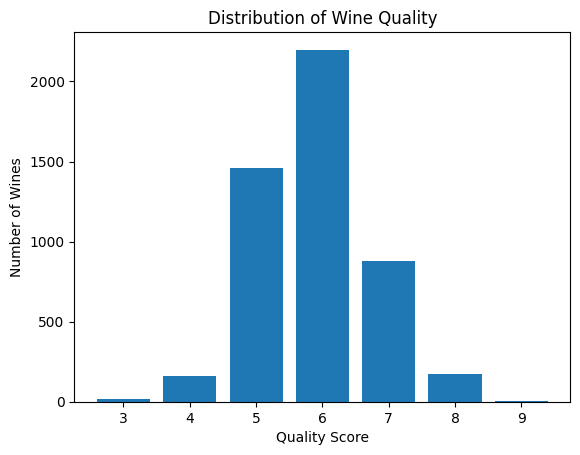

In [66]:
# Show the number of wines for each quality score
quality_count = wine["quality"].value_counts()

plt.bar(quality_count.index, quality_count.values)
plt.xlabel("Quality Score")
plt.ylabel("Number of Wines")
plt.title("Distribution of Wine Quality")
plt.show()

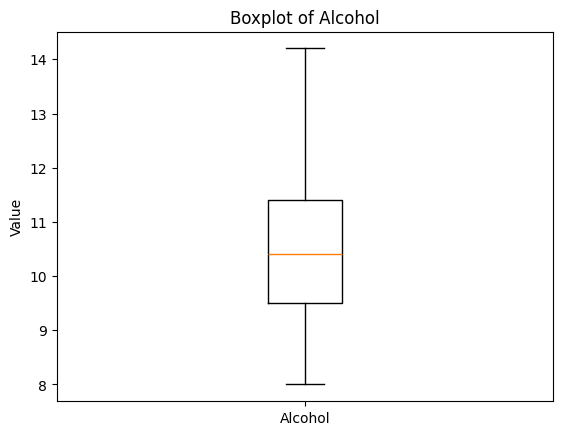

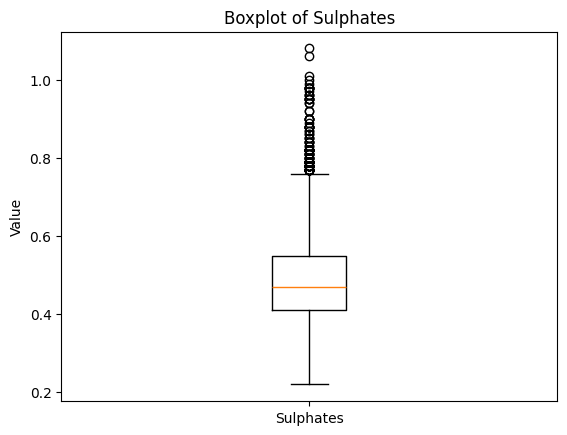

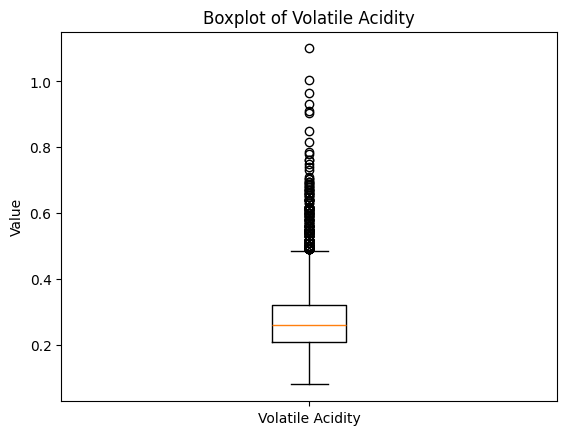

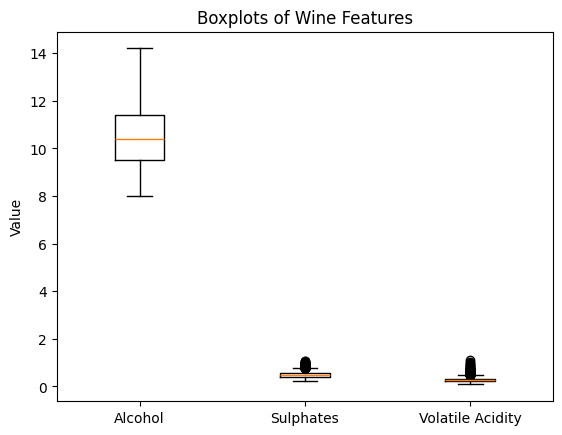

In [67]:
# Use boxplots to check for possible outliers
plt.boxplot(wine["alcohol"])
plt.xticks([1], ["Alcohol"])
plt.ylabel("Value")
plt.title("Boxplot of Alcohol")
plt.show()

plt.boxplot(wine["sulphates"])
plt.xticks([1], ["Sulphates"])
plt.ylabel("Value")
plt.title("Boxplot of Sulphates")
plt.show()

plt.boxplot(wine["volatile acidity"])
plt.xticks([1], ["Volatile Acidity"])
plt.ylabel("Value")
plt.title("Boxplot of Volatile Acidity")
plt.show()

# Show the three boxplots together
plt.boxplot([
    wine["alcohol"],
    wine["sulphates"],
    wine["volatile acidity"]
])

plt.xticks(
    [1, 2, 3],
    ["Alcohol", "Sulphates", "Volatile Acidity"]
)

plt.ylabel("Value")
plt.title("Boxplots of Wine Features")
plt.show()

### 1.2 Data Preparation and Correlation Analysis

I removed duplicate rows and checked for missing values again. I also removed outliers using the IQR method. Finally, I used a correlation heatmap to see which features have a stronger relationship with wine quality.

In [68]:
# Remove duplicate rows
wine_clean = wine.drop_duplicates().copy()

print("Number of Rows Before Cleaning:", len(wine))
print("Number of Rows After Cleaning:", len(wine_clean))

Number of Rows Before Cleaning: 4898
Number of Rows After Cleaning: 3961


In [69]:
# Check for missing values after cleaning
wine_clean.isnull().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

In [70]:
# Use IQR to remove outliers from three features
wine_before_outliers = len(wine_clean)

for column in ["alcohol", "sulphates", "volatile acidity"]:
    Q1 = wine_clean[column].quantile(0.25)
    Q3 = wine_clean[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    wine_clean = wine_clean[
        (wine_clean[column] >= lower_limit) &
        (wine_clean[column] <= upper_limit)
    ]

print("Number of Rows Before Removing Outliers:", wine_before_outliers)
print("Number of Rows After Removing Outliers:", len(wine_clean))

wine_clean[["alcohol", "sulphates", "volatile acidity"]].describe()

Number of Rows Before Removing Outliers: 3961
Number of Rows After Removing Outliers: 3735


,alcohol,sulphates,volatile acidity
count,3735.000000,3735.000000,3735.000000
mean,10.578544,0.481960,0.268942
std,1.195441,0.099038,0.080052
min,8.000000,0.220000,0.080000
25%,9.500000,0.410000,0.210000
50%,10.400000,0.470000,0.260000
75%,11.400000,0.540000,0.320000
max,14.200000,0.760000,0.510000


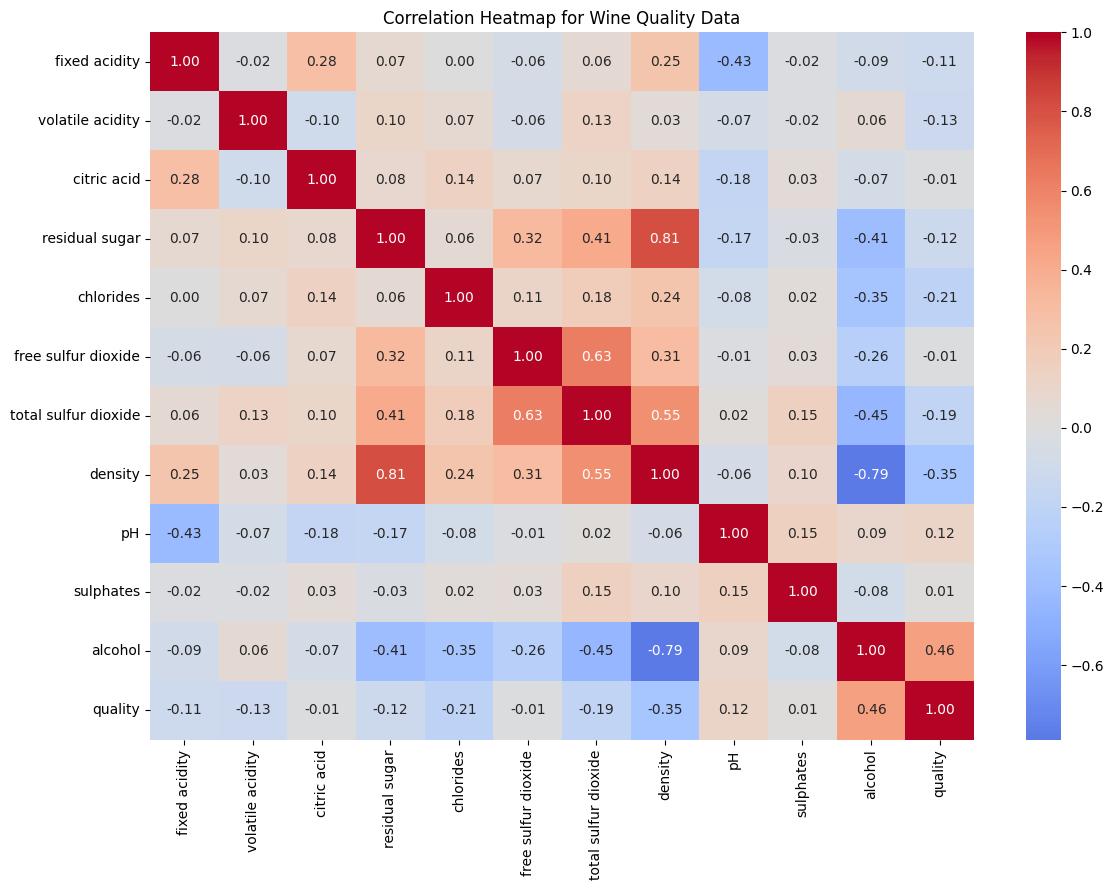

In [71]:
# Show the correlation heatmap
plt.figure(figsize=(12, 9))
sns.heatmap(
    wine_clean.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Correlation Heatmap for Wine Quality Data")
plt.tight_layout()
plt.show()

Alcohol has the strongest positive relationship with wine quality, while density has the strongest negative relationship. Most other features have weaker relationships with quality.

In [72]:
# Separate the input features and target
X_wine = wine_clean.drop("quality", axis=1)
y_wine = wine_clean["quality"]

print("Input shape:", X_wine.shape)
print("Target shape:", y_wine.shape)

Input shape: (3735, 11)
Target shape: (3735,)


### 1.3 Build the Machine Learning Models

I split the dataset into training data and testing data using a 70:30 ratio. Then I built a Linear Regression model and a Decision Tree model using the training data. Both models were tested using the same testing data so that I could compare them fairly.

In [73]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X_wine,
    y_wine,
    test_size=0.3,
    random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 2614
Testing rows: 1121


In [74]:
# Scale features for Linear Regression
scaler_wine = StandardScaler()
X_train_scaled = scaler_wine.fit_transform(X_train)
X_test_scaled = scaler_wine.transform(X_test)

In [75]:
# Build the Decision Tree model
tree_model = DecisionTreeRegressor(
    max_depth=5,
    random_state=42
)
tree_model.fit(X_train, y_train)

# Make predictions
tree_train_pred = tree_model.predict(X_train)
tree_test_pred = tree_model.predict(X_test)

In [76]:
# Build the Linear Regression model
linear_model = LinearRegression()
linear_model.fit(X_train_scaled, y_train)

# Make predictions
linear_train_pred = linear_model.predict(X_train_scaled)
linear_test_pred = linear_model.predict(X_test_scaled)

In [77]:
# Check the Linear Regression result
linear_mae = mean_absolute_error(y_test, linear_test_pred)
linear_rmse = sqrt(mean_squared_error(y_test, linear_test_pred))
linear_r2 = r2_score(y_test, linear_test_pred)

print("Linear Regression")
print("MAE:", round(linear_mae, 4))
print("RMSE:", round(linear_rmse, 4))
print("R2:", round(linear_r2, 4))

Linear Regression
MAE: 0.575
RMSE: 0.7337
R2: 0.2775


In [78]:
# Check the Decision Tree result
tree_mae = mean_absolute_error(y_test, tree_test_pred)
tree_rmse = sqrt(mean_squared_error(y_test, tree_test_pred))
tree_r2 = r2_score(y_test, tree_test_pred)

print("Decision Tree")
print("MAE:", round(tree_mae, 4))
print("RMSE:", round(tree_rmse, 4))
print("R2:", round(tree_r2, 4))

Decision Tree
MAE: 0.57
RMSE: 0.7481
R2: 0.2488


### 1.4 Evaluate and Improve the Model(s) Performance

I compared the two models using MAE, RMSE and R². Then I used GridSearchCV to test different Decision Tree settings and selected the model with the lowest RMSE.

In [79]:
# Compare the training and testing results
linear_train_rmse = sqrt(mean_squared_error(y_train, linear_train_pred))
linear_train_r2 = r2_score(y_train, linear_train_pred)

print("Linear Regression")
print("Train RMSE:", round(linear_train_rmse, 4))
print("Test RMSE:", round(linear_rmse, 4))
print("Train R2:", round(linear_train_r2, 4))
print("Test R2:", round(linear_r2, 4))

print()

tree_train_rmse = sqrt(mean_squared_error(y_train, tree_train_pred))
tree_train_r2 = r2_score(y_train, tree_train_pred)

print("Decision Tree")
print("Train RMSE:", round(tree_train_rmse, 4))
print("Test RMSE:", round(tree_rmse, 4))
print("Train R2:", round(tree_train_r2, 4))
print("Test R2:", round(tree_r2, 4))

Linear Regression
Train RMSE: 0.7421
Test RMSE: 0.7337
Train R2: 0.2801
Test R2: 0.2775

Decision Tree
Train RMSE: 0.6912
Test RMSE: 0.7481
Train R2: 0.3754
Test R2: 0.2488


In [80]:
# Test different Decision Tree settings
param_grid = {
    "max_depth": [3, 4, 5, 6],
    "min_samples_leaf": [1, 5]
}

grid_search = GridSearchCV(
    DecisionTreeRegressor(random_state=42),
    param_grid,
    scoring="neg_root_mean_squared_error",
    cv=5
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)

Best parameters: {'max_depth': 4, 'min_samples_leaf': 5}


In [81]:
# Use the best Decision Tree model
best_tree = grid_search.best_estimator_
best_tree_pred = best_tree.predict(X_test)

best_tree_mae = mean_absolute_error(y_test, best_tree_pred)
best_tree_rmse = sqrt(mean_squared_error(y_test, best_tree_pred))
best_tree_r2 = r2_score(y_test, best_tree_pred)

print("Tuned Decision Tree")
print("MAE:", round(best_tree_mae, 4))
print("RMSE:", round(best_tree_rmse, 4))
print("R2:", round(best_tree_r2, 4))

Tuned Decision Tree
MAE: 0.5721
RMSE: 0.7422
R2: 0.2607


### 1.5 Summarize the Findings

In [82]:
# Compare the final model results
final_results = pd.DataFrame({
    "Model": ["Linear Regression", "Decision Tree (depth=5)", "Tuned Decision Tree"],
    "MAE": [linear_mae, tree_mae, best_tree_mae],
    "RMSE": [linear_rmse, tree_rmse, best_tree_rmse],
    "R2": [linear_r2, tree_r2, best_tree_r2]
})

final_results.round(4)

,Model,MAE,RMSE,R2
0,Linear Regression,0.5750,0.7337,0.2775
1,Decision Tree (depth=5),0.5700,0.7481,0.2488
2,Tuned Decision Tree,0.5721,0.7422,0.2607


In [83]:
# Select the model with the lower RMSE
if linear_rmse < best_tree_rmse:
    print("Preferred model: Linear Regression")
else:
    print("Preferred model: Tuned Decision Tree")

Preferred model: Linear Regression


### Summary of Findings

Both models gave good results. Linear Regression had the lowest RMSE and the highest R², so I selected it as the final model because it gave slightly better predictions.

## 2. Task 2: Unsupervised Learning Using Online Retail Dataset

The aim of Task 2 is to group customers based on their buying behaviour. There is no target column, so this is an unsupervised learning task.

I create Recency, Frequency and Monetary features for each customer. I then use K-means and Hierarchical Clustering to form the customer groups.

### 2.1 Load and Explore the Data

First, I explored the online retail dataset. I checked the data types, missing values, duplicate rows and summary statistics. I also looked for cancelled orders, returned products and invalid values.

In [84]:
# Load the retail data and show the first five rows
retail = pd.read_csv("Dataset/Data/online_retail.csv")
retail.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01/12/2010 08:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,01/12/2010 08:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,01/12/2010 08:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01/12/2010 08:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,01/12/2010 08:26,3.39,17850.0,United Kingdom


In [85]:
# Check the data size and data types
print("Number Of Rows And Columns:", retail.shape)

print()

retail.info()

Number Of Rows And Columns: (541909, 8)

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 33.1 MB


In [86]:
# Check missing values and duplicate rows
print(retail.isnull().sum())

print()

print("Duplicate Rows:", retail.duplicated().sum())

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate Rows: 5268


In [87]:
# Show the data summary
retail.describe()

,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


In [88]:
# Check invalid transactions
print("Cancelled Invoices:",
      retail["InvoiceNo"].astype(str).str.startswith("C").sum())

print("Negative Quantity:",
      (retail["Quantity"] < 0).sum())

print("Zero Or Negative Unit Price:",
      (retail["UnitPrice"] <= 0).sum())

Cancelled Invoices: 9288
Negative Quantity: 10624
Zero Or Negative Unit Price: 2517


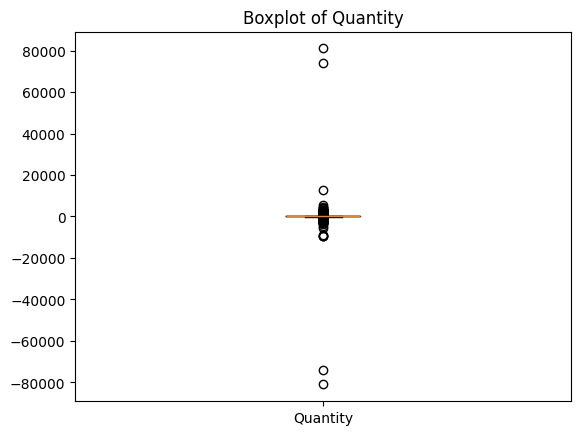

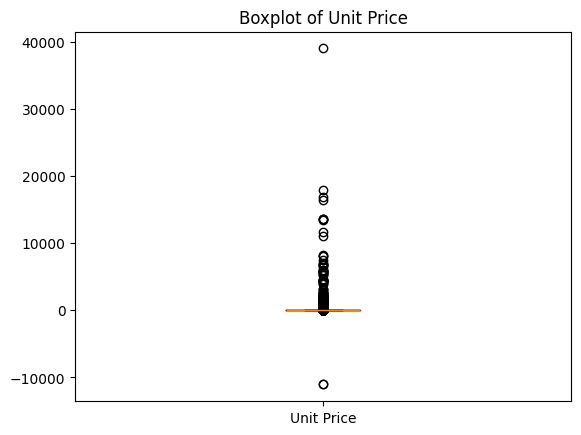

In [89]:
# Use boxplots to check for extreme values
plt.boxplot(retail["Quantity"])
plt.xticks([1], ["Quantity"])
plt.title("Boxplot of Quantity")
plt.show()

plt.boxplot(retail["UnitPrice"])
plt.xticks([1], ["Unit Price"])
plt.title("Boxplot of Unit Price")
plt.show()

### 2.2 Cleanse and Transform the Data

I removed duplicate rows, missing CustomerID values, cancelled orders, returned products and invalid prices. Then I calculated the TotalPrice and created the RFM features: Recency, Frequency and Monetary.

In [90]:
# Remove duplicate rows
retail_clean = retail.drop_duplicates()

# Remove rows with missing CustomerID
retail_clean = retail_clean.dropna(subset=["CustomerID"])

# Keep invoices that are not cancelled
retail_clean = retail_clean[
    ~retail_clean["InvoiceNo"].astype(str).str.startswith("C")
]

# Keep rows with positive quantity and price
retail_clean = retail_clean[
    (retail_clean["Quantity"] > 0) &
    (retail_clean["UnitPrice"] > 0)
]

print("Number of Rows Before Cleaning:", len(retail))
print("Number of Rows After Cleaning:", len(retail_clean))

Number of Rows Before Cleaning: 541909
Number of Rows After Cleaning: 392692


In [91]:
# Change InvoiceDate to date and time format
retail_clean["InvoiceDate"] = pd.to_datetime(
    retail_clean["InvoiceDate"],
    format="%d/%m/%Y %H:%M"
)

# Calculate the total price
retail_clean["TotalPrice"] = (
    retail_clean["Quantity"] * retail_clean["UnitPrice"]
)

# Show the first five rows
retail_clean.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


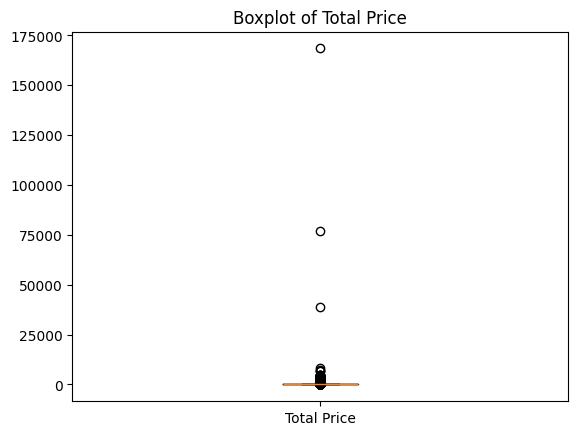

In [92]:
# Check the TotalPrice values
plt.boxplot(retail_clean["TotalPrice"])
plt.xticks([1], ["Total Price"])
plt.title("Boxplot of Total Price")
plt.show()

In [93]:
# Create the RFM features
reference_date = retail_clean["InvoiceDate"].max() + pd.Timedelta(days=1)

last_purchases = retail_clean.groupby("CustomerID")["InvoiceDate"].max()
recency = (reference_date - last_purchases).dt.days

frequency = retail_clean.groupby("CustomerID")["InvoiceNo"].nunique()

monetary = retail_clean.groupby("CustomerID")["TotalPrice"].sum()

rfm = pd.DataFrame({
    "Recency": recency,
    "Frequency": frequency,
    "Monetary": monetary
}).reset_index()

rfm.head()

,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.60
1,12347.0,2,7,4310.00
2,12348.0,75,4,1797.24
3,12349.0,19,1,1757.55
4,12350.0,310,1,334.40


In [94]:
# Use IQR to cap large RFM values
for column in ["Recency", "Frequency", "Monetary"]:
    Q1 = rfm[column].quantile(0.25)
    Q3 = rfm[column].quantile(0.75)
    IQR = Q3 - Q1

    upper_cap = Q3 + 1.5 * IQR

    rfm.loc[rfm[column] > upper_cap, column] = upper_cap
    
rfm[["Recency", "Frequency", "Monetary"]].describe()

,Recency,Frequency,Monetary
count,4338.000000,4338.00000,4338.000000
mean,91.447441,3.48663,1159.010762
std,97.199547,3.04011,1146.777473
min,1.000000,1.00000,3.750000
25%,18.000000,1.00000,306.482500
50%,51.000000,2.00000,668.570000
75%,142.000000,5.00000,1660.597500
max,328.000000,11.00000,3691.770000


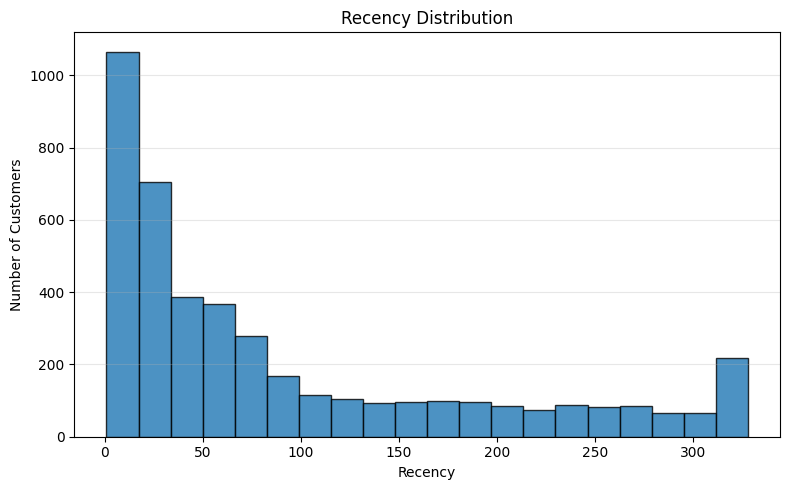

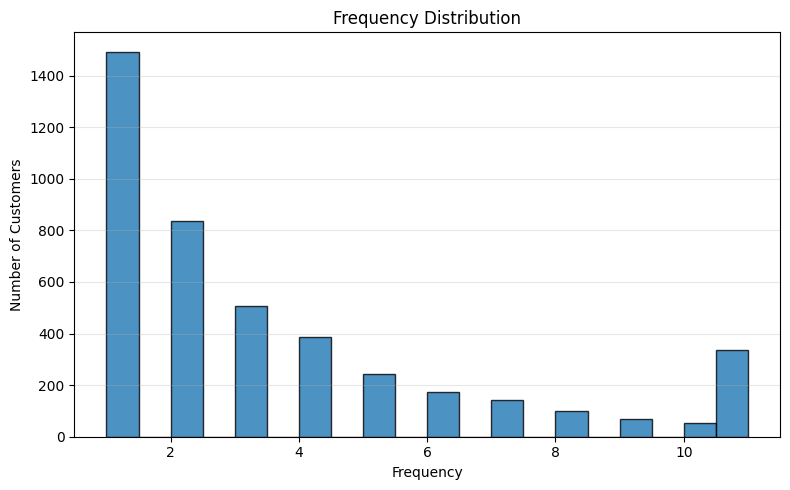

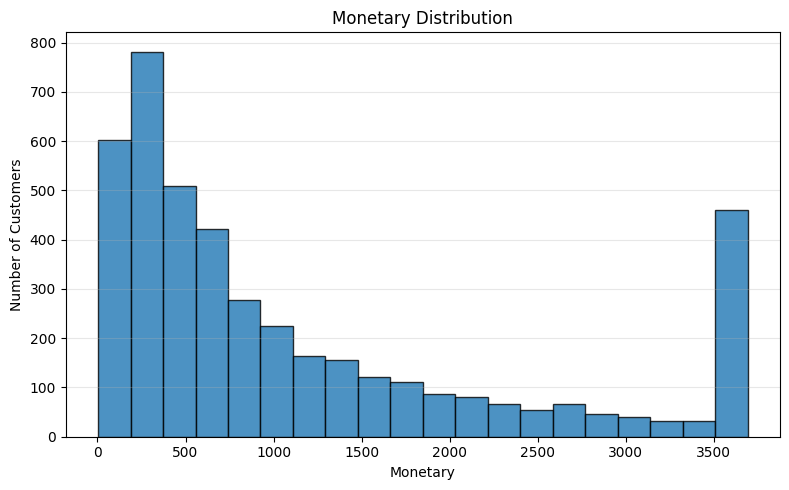

In [95]:
# Show histograms for the RFM features
for column in ["Recency", "Frequency", "Monetary"]:
    plt.figure(figsize=(8, 5))
    plt.hist(
        rfm[column],
        bins=20,
        edgecolor="black",
        alpha=0.8
    )
    plt.title(column + " Distribution")
    plt.xlabel(column)
    plt.ylabel("Number of Customers")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

### 2.3 Build the Clustering Models

I standardised the RFM features because they have different scales. I used the Elbow Method to find a suitable number of clusters. The elbow graph suggested 3 or 4 clusters, so I compared both using the silhouette score. Since 3 clusters had the higher silhouette score, I used 3 clusters for the final model.

In [96]:
# Select and standardise the RFM features
rfm_features = rfm[["Recency", "Frequency", "Monetary"]]

scaler_rfm = StandardScaler()
rfm_scaled = scaler_rfm.fit_transform(rfm_features)

print(rfm_scaled.shape)

(4338, 3)


In [97]:
# Find the SSE for 1 to 10 clusters
sse = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42
    )
    kmeans.fit(rfm_scaled)
    sse.append(kmeans.inertia_)

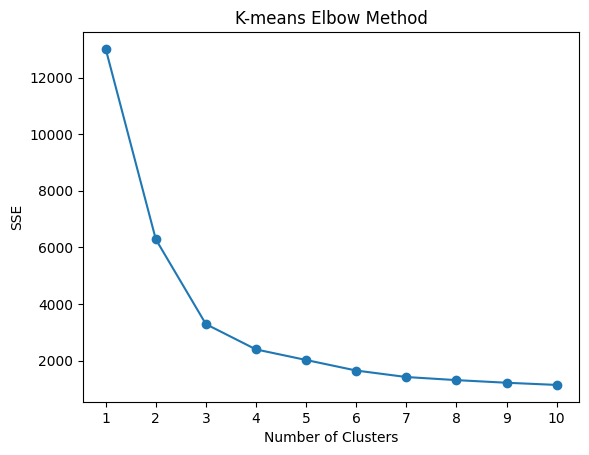

In [98]:
# Plot the elbow graph
plt.plot(range(1, 11), sse, marker="o")
plt.title("K-means Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("SSE")
plt.xticks(range(1, 11))
plt.show()

In [99]:
# Compare 3 and 4 clusters
for number_of_clusters in [3, 4]:

    model = KMeans(
        n_clusters=number_of_clusters,
        random_state=42
    )

    cluster_labels = model.fit_predict(rfm_scaled)

    score = silhouette_score(
        rfm_scaled,
        cluster_labels
    )

    print(
        number_of_clusters,
        "clusters:",
        round(score, 4)
    )

3 clusters: 0.5095
4 clusters: 0.4743


The elbow graph suggested that 3 or 4 clusters could be used. I tested both and compared their silhouette scores. Since 3 clusters had the higher score, I selected 3 clusters.

In [100]:
# Build the K-means model with 3 clusters
kmeans_model = KMeans(
    n_clusters=3,
    random_state=42
)


rfm["KMeans_Cluster"] = kmeans_model.fit_predict(rfm_scaled)
print(rfm["KMeans_Cluster"].value_counts().sort_index())

KMeans_Cluster
0    2333
1     955
2    1050
Name: count, dtype: int64


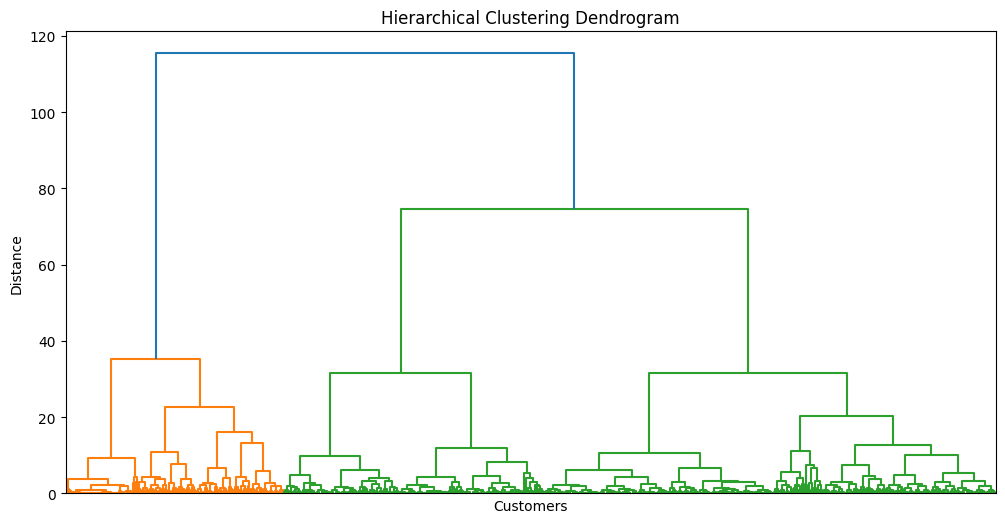

In [101]:
# Plot the dendrogram
Z = shc.linkage(rfm_scaled, method="ward")

plt.figure(figsize=(12, 6))
shc.dendrogram(Z, no_labels=True)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Customers")
plt.ylabel("Distance")
plt.show()

In [102]:
# Build the Hierarchical Clustering model with 3 clusters
hierarchical_model = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward"
)

rfm["Hierarchical_Cluster"] = hierarchical_model.fit_predict(rfm_scaled)
print(rfm["Hierarchical_Cluster"].value_counts().sort_index())

Hierarchical_Cluster
0    1019
1    2112
2    1207
Name: count, dtype: int64


### 2.4 Evaluate and Compare the Models

I compared K-means and Hierarchical Clustering using the silhouette score. A higher silhouette score means the clusters are better separated. K-means had the higher score, so I selected it as the final clustering model.

In [103]:
# Find the K-means silhouette score
kmeans_silhouette = silhouette_score(
    rfm_scaled,
    rfm["KMeans_Cluster"]
)

print("K-means Silhouette Score:", round(kmeans_silhouette, 4))

K-means Silhouette Score: 0.5095


In [104]:
# Find the Hierarchical silhouette score
hierarchical_silhouette = silhouette_score(
    rfm_scaled,
    rfm["Hierarchical_Cluster"]
)

print("Hierarchical Silhouette Score:", round(hierarchical_silhouette, 4))

Hierarchical Silhouette Score: 0.4651


In [105]:
# Compare the two clustering models
clustering_results = pd.DataFrame({
    "Model": ["K-means", "Hierarchical Clustering"],
    "Number of Clusters": [3, 3],
    "Silhouette Score": [kmeans_silhouette, hierarchical_silhouette]
})

clustering_results.round(4)

,Model,Number of Clusters,Silhouette Score
0,K-means,3,0.5095
1,Hierarchical Clustering,3,0.4651


In [106]:
if kmeans_silhouette > hierarchical_silhouette:
    print("Preferred clustering model: K-means")
else:
    print("Preferred clustering model: Hierarchical")

Preferred clustering model: K-means


### 2.5 Summarize and Interpret

I use the average Recency, Frequency and Monetary values to understand each cluster. I then give each cluster a simple customer segment name.

In [107]:
# Use the K-means clusters for the final customer groups
rfm["Selected_Cluster"] = rfm["KMeans_Cluster"]

# Find the average RFM values for each cluster
segment_summary = rfm.groupby("Selected_Cluster")[
    ["Recency", "Frequency", "Monetary"]
].mean().round(2)

# Count the customers in each cluster
segment_summary["Number of Customers"] = rfm.groupby(
    "Selected_Cluster"
).size()

# Add a name for each cluster
segment_summary["Segment Name"] = [
    "Recent Occasional",
    "High-Value Loyal",
    "At-Risk Low-Value"
]

segment_summary

,Recency,Frequency,Monetary,Number of Customers,Segment Name
Selected_Cluster,,,,,
0,48.96,2.47,731.94,2333,Recent Occasional
1,26.68,8.19,3008.52,955,High-Value Loyal
2,244.76,1.47,425.75,1050,At-Risk Low-Value


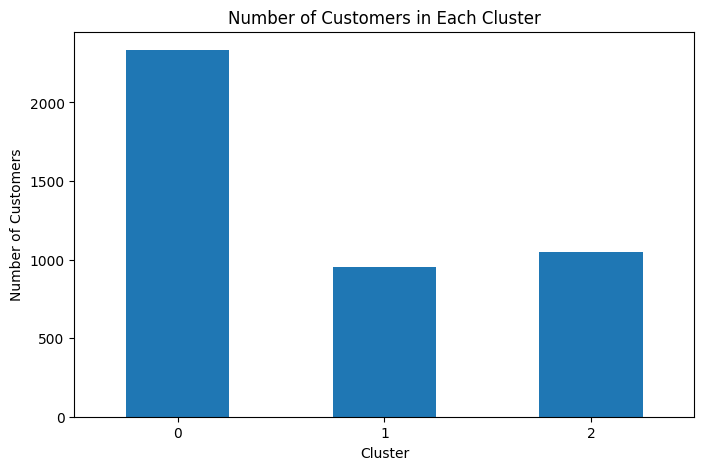

In [108]:
# Plot the number of customers in each cluster
segment_summary["Number of Customers"].plot(
    kind="bar",
    figsize=(8, 5)
)
plt.title("Number of Customers in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.show()

K-means had the higher silhouette score, so it was selected as the final clustering model. The customer groups were then named based on their average Recency, Frequency and Monetary values.

### High-Value Loyal
These customers buy often, spend the most money and purchased recently. They are the business's best customers. Loyalty rewards and special offers can help keep them.

### Recent Occasional
These customers purchased recently but do not buy very often. The business can encourage them to buy again by sending personalised offers.

### At-Risk Low-Value
These customers have not purchased for a long time and spend the least. The business can try to bring them back with discounts or reminder emails.